[![Abrir no Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lalvim/DataMining/blob/main/notebooks/unidade_07/07_04_fluxo_de_decisao.ipynb)

# Unidade VII — Detecção de *Outliers*

## Fluxo de decisão para escolher e avaliar métodos

**Carga estimada:** 1 hora  
**Pré-requisitos:** caracterização de outliers e métodos univariados e multivariados.

> **Pergunta norteadora:** como passar de um problema de investigação para uma escolha de método justificável, testada e revisável?

A escolha não deve ser feita pelo nome do algoritmo nem pelo maior escore observado. Este notebook organiza diagnósticos, candidatos, testes de sensibilidade e critérios operacionais em uma sequência documentada.

## Objetivos de aprendizagem

Ao concluir este notebook, você será capaz de:

- formular finalidade, unidade, referência e capacidade de investigação;
- executar diagnósticos antes de selecionar um detector;
- relacionar características dos dados a famílias de métodos;
- comparar candidatos sem escolher parâmetros no conjunto de teste;
- incorporar sensibilidade, validação temporal e custo dos erros;
- registrar uma decisão que possa ser auditada e revista.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import precision_score, recall_score
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 120})

## 1. O método vem depois da decisão analítica

Antes de calcular qualquer escore, produza uma ficha com:

| Decisão | Pergunta mínima |
|---|---|
| finalidade | qual evento será investigado e qual ação pode resultar? |
| unidade | será avaliada uma leitura, transação, janela ou entidade? |
| referência | com qual população e período o caso será comparado? |
| representação | o desvio depende de uma variável, combinação, contexto ou sequência? |
| capacidade | quantos alertas podem ser revisados e em quanto tempo? |
| erro | qual o custo de falso alerta e de caso perdido? |
| confirmação | como e quando um rótulo confiável será obtido? |

Sem essas respostas, um limiar pode ser matematicamente reproduzível e operacionalmente inútil.

## 2. Ilustração do fluxo de decisão

O diagrama apresenta rotas iniciais. As perguntas reduzem o conjunto de candidatos, mas não substituem comparação empírica e conhecimento do domínio.

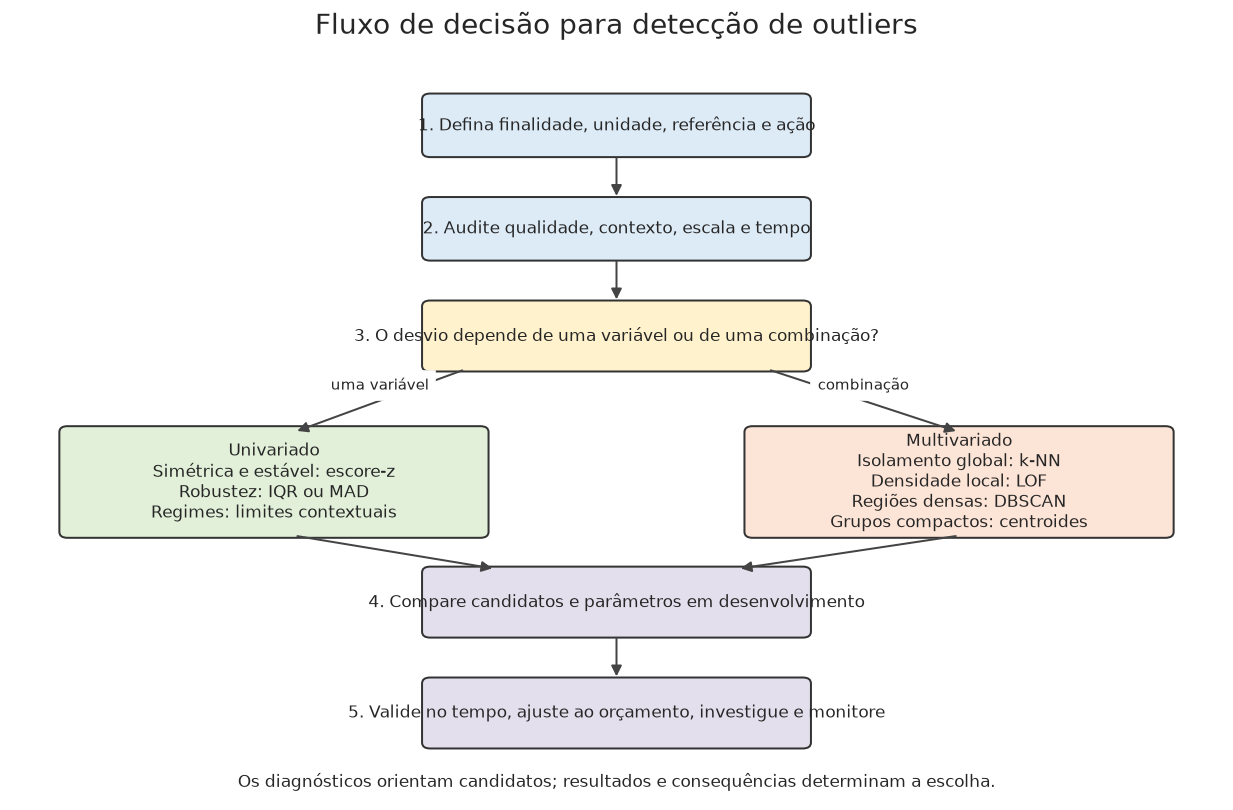

In [2]:
fig, ax = plt.subplots(figsize=(13, 8))
ax.set_xlim(0, 12)
ax.set_ylim(0, 10)
ax.axis("off")

def caixa(x, y, largura, altura, texto, cor, tamanho=10):
    bloco = FancyBboxPatch(
        (x, y), largura, altura,
        boxstyle="round,pad=0.03,rounding_size=0.08",
        facecolor=cor, edgecolor="#333333", linewidth=1.2,
    )
    ax.add_patch(bloco)
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", fontsize=tamanho, wrap=True)
    return (x, y, largura, altura)

def seta(origem, destino, rotulo=None):
    x1, y1 = origem
    x2, y2 = destino
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=13, color="#444444", linewidth=1.2))
    if rotulo:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.15, rotulo, ha="center", fontsize=9, backgroundcolor="white")

caixa(4.1, 8.7, 3.8, 0.8, "1. Defina finalidade, unidade, referência e ação", "#DDEBF7")
caixa(4.1, 7.3, 3.8, 0.8, "2. Audite qualidade, contexto, escala e tempo", "#DDEBF7")
caixa(4.1, 5.8, 3.8, 0.9, "3. O desvio depende de uma variável ou de uma combinação?", "#FFF2CC")
caixa(0.5, 3.55, 4.2, 1.45, "Univariado\nSimétrica e estável: escore-z\nRobustez: IQR ou MAD\nRegimes: limites contextuais", "#E2F0D9")
caixa(7.3, 3.55, 4.2, 1.45, "Multivariado\nIsolamento global: k-NN\nDensidade local: LOF\nRegiões densas: DBSCAN\nGrupos compactos: centroides", "#FCE4D6")
caixa(4.1, 2.2, 3.8, 0.9, "4. Compare candidatos e parâmetros em desenvolvimento", "#E4DFEC")
caixa(4.1, 0.7, 3.8, 0.9, "5. Valide no tempo, ajuste ao orçamento, investigue e monitore", "#E4DFEC")

seta((6.0, 8.7), (6.0, 8.1))
seta((6.0, 7.3), (6.0, 6.7))
seta((4.5, 5.8), (2.8, 4.95), "uma variável")
seta((7.5, 5.8), (9.4, 4.95), "combinação")
seta((2.8, 3.55), (4.8, 3.1))
seta((9.4, 3.55), (7.2, 3.1))
seta((6.0, 2.2), (6.0, 1.6))
ax.set_title("Fluxo de decisão para detecção de outliers", fontsize=17, pad=15)
ax.text(6, 0.15, "Os diagnósticos orientam candidatos; resultados e consequências determinam a escolha.", ha="center", fontsize=10)
plt.show()

## 3. Diagnósticos antes da escolha

Os “testes” desta etapa são diagnósticos, não provas automáticas de qual algoritmo vencerá.

| Diagnóstico | O que verificar | Consequência para a escolha |
|---|---|---|
| qualidade | ausências, duplicatas, unidades e limites físicos | corrigir o pipeline antes de modelar, preservando o dado bruto |
| distribuição marginal | assimetria, caudas, empates e múltiplos modos | decidir entre referência clássica, robusta ou contextual |
| escala | amplitudes e unidades muito diferentes | transformar ou padronizar antes de usar distâncias |
| dependência | correlações, relações não lineares e combinações raras | considerar abordagem multivariada |
| densidade e geometria | regiões compactas, formas curvas e densidades diferentes | selecionar candidatos globais, locais ou baseados em grupos |
| dimensionalidade | número de atributos, redundância e concentração das distâncias | selecionar atributos e testar estabilidade da representação |
| tempo | tendência, sazonalidade e mudança de regime | validar em períodos posteriores e criar referências contextuais |
| rótulos e orçamento | confirmações disponíveis e capacidade de revisão | escolher métricas, limiar e tamanho da lista operacional |

## 4. Estudo guiado: escolher candidatos

Considere medições de duas variáveis de um processo industrial. Há dois regimes operacionais com densidades diferentes e alguns eventos injetados apenas para avaliação didática. A finalidade é priorizar 15 casos para inspeção; os rótulos não participam do ajuste.

,diagnóstico,resultado,leitura
0,objetos,295.000,amostra moderada
1,atributos,2.000,problema multivariado
2,ausências,0.000,sem ausência
3,duplicatas,0.000,sem duplicidade
4,assimetria máxima,0.638,inspecionar transformação
5,razão p90/p10 da distância ao 10º vizinho,7.219,densidade varia no espaço


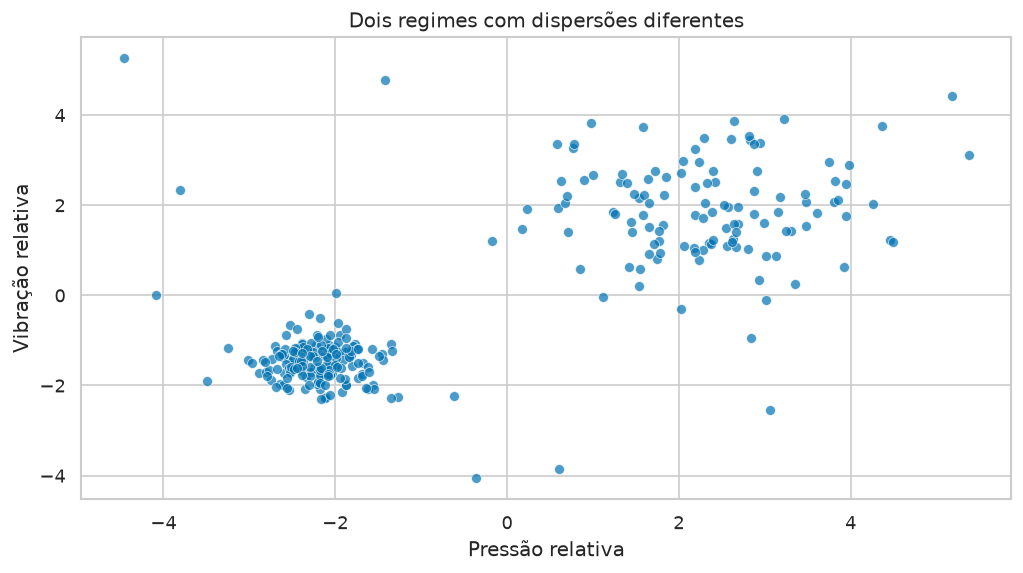

In [3]:
rng = np.random.default_rng(RANDOM_STATE)
X_normal, _ = make_blobs(
    n_samples=[170, 110], centers=[(-2.2, -1.5), (2.3, 2.0)],
    cluster_std=[0.4, 1.0], random_state=RANDOM_STATE,
)
X_eventos = rng.uniform(low=[-5.5, -4.5], high=[5.5, 5.5], size=(15, 2))
X = np.vstack([X_normal, X_eventos])
y_avaliacao = np.r_[np.zeros(len(X_normal), dtype=int), np.ones(len(X_eventos), dtype=int)]
dados = pd.DataFrame(X, columns=["pressao_relativa", "vibracao_relativa"])
X_pad = StandardScaler().fit_transform(X)

vizinhos_diagnostico = NearestNeighbors(n_neighbors=11).fit(X_pad)
distancias_diagnostico, _ = vizinhos_diagnostico.kneighbors(X_pad)
distancia_10 = distancias_diagnostico[:, -1]
resumo_diagnostico = pd.DataFrame({
    "diagnóstico": ["objetos", "atributos", "ausências", "duplicatas", "assimetria máxima", "razão p90/p10 da distância ao 10º vizinho"],
    "resultado": [len(dados), dados.shape[1], int(dados.isna().sum().sum()), int(dados.duplicated().sum()), round(dados.skew().abs().max(), 3), round(np.quantile(distancia_10, 0.9) / np.quantile(distancia_10, 0.1), 3)],
    "leitura": ["amostra moderada", "problema multivariado", "sem ausência", "sem duplicidade", "inspecionar transformação", "densidade varia no espaço"],
})
display(resumo_diagnostico)

ax = sns.scatterplot(data=dados, x="pressao_relativa", y="vibracao_relativa", color="#0072B2", s=35, alpha=0.7)
ax.set(title="Dois regimes com dispersões diferentes", xlabel="Pressão relativa", ylabel="Vibração relativa")
plt.show()

A finalidade depende da combinação de duas variáveis, então uma regra univariada não é suficiente. A variação das distâncias locais sugere densidades diferentes: LOF entra como candidato principal, mas deve ser comparado com isolamento global, DBSCAN e distância a centroides. A padronização é ajustada antes das distâncias porque as unidades podem divergir em aplicações reais.

## 5. Comparar candidatos sob o mesmo orçamento

Para escores contínuos, selecionaremos os 15 primeiros casos. Para DBSCAN, manteremos todos os pontos marcados como ruído e registraremos que a quantidade pode diferir. Os rótulos sintéticos aparecem somente nesta avaliação final. Em um projeto real, parâmetros seriam definidos em desenvolvimento e avaliados em período posterior.

,método,alertas,precisão,revocação
1,LOF (top 15),15,0.733,0.733
3,centroide (top 15),15,0.667,0.667
0,k-NN (top 15),15,0.600,0.600
2,DBSCAN (ruído),28,0.393,0.733


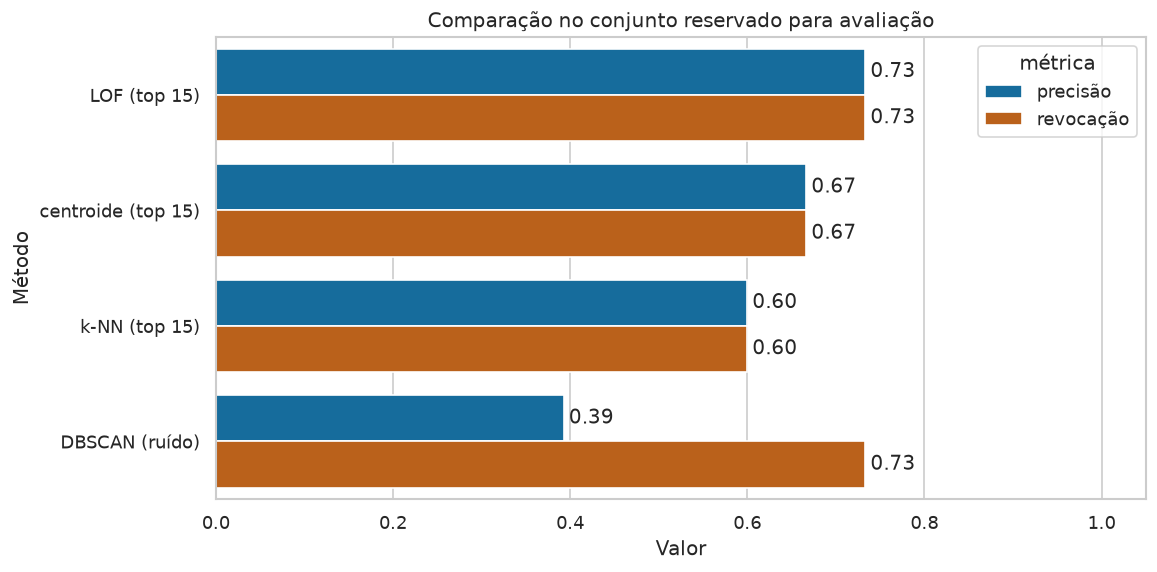

In [4]:
ORCAMENTO = 15

def top_n(escores, quantidade):
    """Converte escores crescentes de anomalia em lista binária priorizada."""
    indices = np.argsort(escores)[-quantidade:]
    alertas = np.zeros(len(escores), dtype=int)
    alertas[indices] = 1
    return alertas

distancias, _ = NearestNeighbors(n_neighbors=16).fit(X_pad).kneighbors(X_pad)
escore_knn = distancias[:, -1]
modelo_lof = LocalOutlierFactor(n_neighbors=15).fit(X_pad)
escore_lof = -modelo_lof.negative_outlier_factor_
alerta_dbscan = (DBSCAN(eps=0.3, min_samples=8).fit_predict(X_pad) == -1).astype(int)
modelo_kmeans = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE).fit(X_pad)
escore_centroide = np.linalg.norm(X_pad - modelo_kmeans.cluster_centers_[modelo_kmeans.labels_], axis=1)

predicoes = {
    "k-NN (top 15)": top_n(escore_knn, ORCAMENTO),
    "LOF (top 15)": top_n(escore_lof, ORCAMENTO),
    "DBSCAN (ruído)": alerta_dbscan,
    "centroide (top 15)": top_n(escore_centroide, ORCAMENTO),
}
linhas = []
for metodo, previsto in predicoes.items():
    linhas.append({
        "método": metodo,
        "alertas": int(previsto.sum()),
        "precisão": precision_score(y_avaliacao, previsto, zero_division=0),
        "revocação": recall_score(y_avaliacao, previsto, zero_division=0),
    })
comparacao = pd.DataFrame(linhas).sort_values(["precisão", "revocação"], ascending=False)
display(comparacao.round(3))

ax = sns.barplot(data=comparacao.melt(id_vars="método", value_vars=["precisão", "revocação"], var_name="métrica", value_name="valor"), x="valor", y="método", hue="métrica", palette=["#0072B2", "#D55E00"])
ax.set(title="Comparação no conjunto reservado para avaliação", xlabel="Valor", ylabel="Método", xlim=(0, 1.05))
for recipiente in ax.containers:
    ax.bar_label(recipiente, fmt="%.2f", padding=3)
plt.show()

## 6. Registrar a decisão

A escolha final deve combinar adequação estrutural e resultado fora do desenvolvimento. Use um registro como este:

| Campo | Registro esperado |
|---|---|
| finalidade e orçamento | evento investigado e quantidade máxima de alertas |
| representação | atributos, transformações, escala e contexto |
| candidatos | métodos incluídos e motivo das exclusões |
| parâmetros | origem da escolha e faixa testada |
| avaliação | período reservado, precisão, revocação, custo e incerteza |
| sensibilidade | estabilidade do ranking sob parâmetros e amostras próximas |
| decisão | método, limiar e justificativa vinculada à finalidade |
| governança | revisão humana, preservação do dado, contestação e monitoramento |

Neste exemplo, a decisão é **LOF com os 15 primeiros escores**: ele é coerente com a densidade variável, respeita o orçamento e obteve a maior precisão e revocação entre as listas de 15 casos. O DBSCAN alcançou a mesma revocação, mas gerou 28 alertas e menor precisão. A escolha continua condicionada à estabilidade em valores próximos de `n_neighbors` e ao desempenho em períodos posteriores. Se outro método vencer por pequena margem, estabilidade, custo e interpretabilidade devem decidir — não a terceira casa decimal.

## 7. Atividades

**U07-NB04-V01.** Explique por que um teste de normalidade, uma medida de assimetria ou um gráfico não escolhe automaticamente o detector.

**U07-NB04-E01.** Uma variável é aproximadamente simétrica, estável e sem contaminação evidente. Proponha método inicial, diagnóstico complementar e condição que faria você trocar de método.

**U07-NB04-E02.** Há três regiões não convexas, densidade semelhante e pontos isolados. Percorra o fluxo, proponha um candidato principal e dois parâmetros que precisam de análise de sensibilidade.

**U07-NB04-E03.** Reexecute o estudo com `n_neighbors` igual a 8, 15 e 30. Compare a interseção dos dez primeiros alertas do LOF e registre se a recomendação permanece estável.

**U07-NB04-E04.** Elabore um registro de decisão para um cenário de sua escolha, incluindo todos os campos da tabela e uma condição explícita para suspender ou revisar o detector.

## 8. Síntese

- A escolha começa pela finalidade, unidade, referência e ação possível.
- Diagnósticos de qualidade, distribuição, escala, dependência, geometria e tempo orientam candidatos.
- Métodos univariados e multivariados operacionalizam noções diferentes de desvio.
- Parâmetros devem ser escolhidos em desenvolvimento e avaliados em dados posteriores ou reservados.
- Orçamento, custo, estabilidade, revisão e monitoramento fazem parte da decisão técnica.

## Referências

- HAN, J.; PEI, J.; TONG, H. *Data Mining: Concepts and Techniques*. 4. ed. Morgan Kaufmann, 2023. Cap. 11.
- AGGARWAL, C. C. *Outlier Analysis*. 2. ed. Springer, 2017.
- CHANDOLA, V.; BANERJEE, A.; KUMAR, V. Anomaly detection: a survey. *ACM Computing Surveys*, v. 41, n. 3, 2009.

Os dados, o diagrama e as figuras deste notebook são sintéticos e autorais.